In [28]:
# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
REAL_WATERFALL_PATH = './real data/waterfall_CF_r3_11.575GHz.npy'
REAL_TIME_AXIS_PATH = './real data/datetime_waterfall_CF_r3_11.575GHz.npy'
REAL_VELOCITY_AXIS_PATH = './real data/rel_vel_waterfall_CF_r3_11.575GHz.npy'

SIM_DATA_ROOT = './sim new'
SIM_RUN_FILTER = '20260206_213348'   # only folders containing this text are scanned

# Real-data preprocessing
DOWNSAMPLE_METHOD = 'mean'            # 'mean' or 'median'
N_VEL_OUT = 300
FLIP_REAL_VELOCITY = True             # kept from the original v3 workflow

# Template and search window. Slices are [start, end).
TIME_SLICE = (125, 160)
# TIME_SLICE = (190, 215)
VEL_SLICE = (180, 290)
SEARCH_MARGIN_T = 10                  # rows around TIME_SLICE to search; None searches all times
SEARCH_MARGIN_V = 25                  # columns around VEL_SLICE to search; None searches all velocities
MAX_TIME_LAG_ROWS = 10                # max time lag in rows (1Hz = 1 row/sec); restricts scoring window for speed

# Simulation mask construction
SIM_SIGMA_KMS = 0.07
SIM_MASK_FILL_EMPTY = 'zeros'         # 'zeros' or 'uniform'

# Domain interpretation and thresholding
REAL_SOURCE_MODE = 'ridge_db'         # 'ridge_db', 'valley_db', or 'linear'
REAL_LINEAR_THRESHOLD = 2e-15

# Result ranking and plotting
MAX_ABS_TIME_LAG_SEC = 10.0
MAKE_HEATMAP_FOR_TOP_MATCH = True
TOP_MATCH_RANK = 0                    # 0 = best restricted match
SAVE_DEBUG_PATCHES = True
DEBUG_DIR = 'debug_patches'
OUTPUT_DIR = '.'
VERBOSE_SKIPS = False


In [29]:
# ------------------------------------------------------------
# Imports
# ------------------------------------------------------------
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


In [30]:
# ------------------------------------------------------------
# Plotting helpers
# ------------------------------------------------------------
def _waterfall_extent(vel_centers_kms, t1hz):
    duration_min = (t1hz[-1] - t1hz[0]).total_seconds() / 60.0
    return [vel_centers_kms.min(), vel_centers_kms.max(), duration_min, 0]


def _value_limits(W, upper_clip=None, lo=2, hi=98, fallback=None):
    valid = np.asarray(W)[np.isfinite(W)]
    if upper_clip is not None:
        valid = valid[valid < upper_clip]
    if valid.size:
        return np.percentile(valid, [lo, hi])
    if fallback is not None:
        return fallback
    return float(np.nanmin(W)), float(np.nanmax(W))


def _rect_from_indices(t0, t1, v0, v1, vel_centers_kms):
    x0 = vel_centers_kms[v0]
    x1 = vel_centers_kms[v1 - 1]
    y0 = t0 / 60.0
    y1 = t1 / 60.0
    return x0, x1, y0, y1


def create_waterfallplot(W, vel_centers_kms, t1hz, title):
    vmin, vmax = _value_limits(W, upper_clip=240, lo=5, hi=95, fallback=(170, 185))
    plt.figure(figsize=(12, 5))
    im = plt.imshow(
        W,
        aspect='auto',
        extent=_waterfall_extent(vel_centers_kms, t1hz),
        cmap='jet_r',
        vmin=vmin,
        vmax=vmax,
        interpolation='bilinear',
        origin='upper',
    )
    plt.axvline(0, color='white', linestyle='--', linewidth=1.5, alpha=0.8, label='Zero velocity')
    plt.xlabel('Relative Velocity (km/s)')
    plt.ylabel('Time into pass (min)')
    plt.title(title)
    plt.legend(loc='upper right')
    plt.colorbar(im, label='Waterfall value')
    plt.tight_layout()
    plt.show()


def plot_satellite_match(
    file_name,
    heatmap_payloads,
    vel_centers_kms,
    t1hz,
    time_slice,
    vel_slice,
    best_i=None,
    best_j=None,
    best_score=None,
    best_lag_t_sec=None,
    best_lag_v_kms=None,
    max_abs_time_lag_sec=None,
):
    payload = next((item for item in heatmap_payloads if item['file'] == file_name), None)
    if payload is None:
        raise ValueError(f'No payload found for {file_name}')

    score_map = payload['score_map']
    sim_1hz = payload['sim_1hz']
    real_1hz = payload['real_1hz']
    real_patch = payload['real_patch']
    sim_search = payload['sim_search']
    lag_t_sec = payload['lag_t_sec']
    lag_v_kms = payload['lag_v_kms']

    best_i = payload['best_i'] if best_i is None else best_i
    best_j = payload['best_j'] if best_j is None else best_j
    best_score = payload['best_score'] if best_score is None else best_score
    best_lag_t_sec = payload['best_lag_t_sec'] if best_lag_t_sec is None else best_lag_t_sec
    best_lag_v_kms = payload['best_lag_v_kms'] if best_lag_v_kms is None else best_lag_v_kms

    start_t, end_t = time_slice
    start_v, end_v = vel_slice
    patch_h = end_t - start_t
    patch_w = end_v - start_v

    extent = _waterfall_extent(vel_centers_kms, t1hz)
    real_vmin, real_vmax = _value_limits(real_1hz, upper_clip=None)
    sim_vmin, sim_vmax = _value_limits(sim_1hz, upper_clip=None)

    sim_patch = None
    if best_i is not None and best_j is not None:
        if best_i + patch_h <= sim_search.shape[0] and best_j + patch_w <= sim_search.shape[1]:
            sim_patch = sim_search[best_i:best_i + patch_h, best_j:best_j + patch_w]

    fig = plt.figure(figsize=(18, 13))
    gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.0, 1.15])
    ax00 = fig.add_subplot(gs[0, 0])
    ax01 = fig.add_subplot(gs[0, 1])
    ax02 = fig.add_subplot(gs[0, 2])
    ax10 = fig.add_subplot(gs[1, 0])
    ax11 = fig.add_subplot(gs[1, 1])
    ax12 = fig.add_subplot(gs[1, 2])
    ax20 = fig.add_subplot(gs[2, :])

    im = ax00.imshow(real_1hz, aspect='auto', origin='upper', extent=extent, cmap='jet_r',
                     vmin=real_vmin, vmax=real_vmax, interpolation='nearest')
    x0, x1, y0, y1 = _rect_from_indices(start_t, end_t, start_v, end_v, vel_centers_kms)
    ax00.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='white', linewidth=2))
    ax00.axvline(0, color='white', linestyle='--', linewidth=1.2)
    ax00.set_title('Real waterfall with selected patch')
    ax00.set_xlabel('Relative Velocity (km/s)')
    ax00.set_ylabel('Time into pass (min)')
    fig.colorbar(im, ax=ax00, label='Real value')

    im = ax01.imshow(sim_1hz, aspect='auto', origin='upper', extent=extent, cmap='jet_r',
                     vmin=sim_vmin, vmax=sim_vmax, interpolation='nearest')
    ex0, ex1, ey0, ey1 = _rect_from_indices(start_t, end_t, start_v, end_v, vel_centers_kms)
    ax01.add_patch(plt.Rectangle((ex0, ey0), ex1 - ex0, ey1 - ey0, fill=False,
                                 edgecolor='cyan', linewidth=2, label='Expected region'))
    if best_i is not None and best_j is not None:
        bx0, bx1, by0, by1 = _rect_from_indices(best_i, best_i + patch_h, best_j, best_j + patch_w, vel_centers_kms)
        ax01.add_patch(plt.Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False,
                                     edgecolor='lime', linewidth=2, label='Best match'))
    ax01.axvline(0, color='white', linestyle='--', linewidth=1.2)
    ax01.set_title(f'Simulation mask: {file_name}')
    ax01.set_xlabel('Relative Velocity (km/s)')
    ax01.set_ylabel('Time into pass (min)')
    ax01.legend(loc='upper right')
    fig.colorbar(im, ax=ax01, label='Simulation mask')

    t_mask = np.ones_like(lag_t_sec, dtype=bool)
    if max_abs_time_lag_sec is not None:
        t_mask = np.abs(lag_t_sec) <= max_abs_time_lag_sec
    score_map_plot = score_map[t_mask, :]
    lag_t_sec_plot = lag_t_sec[t_mask]

    if score_map_plot.size and lag_t_sec_plot.size:
        im = ax02.imshow(score_map_plot, aspect='auto', origin='lower',
                         extent=[lag_v_kms[0], lag_v_kms[-1], lag_t_sec_plot[0], lag_t_sec_plot[-1]],
                         interpolation='nearest')
        ax02.scatter(best_lag_v_kms, best_lag_t_sec, marker='x', s=100, color='white')
        fig.colorbar(im, ax=ax02, label='mask score')
    ax02.axvline(0, linestyle='--', linewidth=1, color='white')
    ax02.axhline(0, linestyle='--', linewidth=1, color='white')
    ax02.set_xlabel('Velocity lag (km/s)')
    ax02.set_ylabel('Time lag (s)')
    ax02.set_title(f'Score heatmap, best score={best_score:.4f}')

    im = ax10.imshow(real_patch, aspect='auto', origin='upper')
    ax10.set_title('Real template patch (linear, thresholded)')
    ax10.set_xlabel('Velocity column')
    ax10.set_ylabel('Time row')
    fig.colorbar(im, ax=ax10)

    if sim_patch is not None:
        im = ax11.imshow(sim_patch, aspect='auto', origin='upper')
        ax11.set_title('Best simulation patch')
        ax11.set_xlabel('Velocity column')
        ax11.set_ylabel('Time row')
        fig.colorbar(im, ax=ax11)
    else:
        ax11.text(0.5, 0.5, 'Simulation patch unavailable', ha='center', va='center')
        ax11.set_title('Best simulation patch')
        ax11.set_axis_off()

    ax12.axis('off')

    if sim_patch is not None:
        tol = 1e-20
        real_y, real_x = np.nonzero(np.abs(real_patch) > tol)
        sim_y, sim_x = np.nonzero(np.abs(sim_patch) > tol)
        ax20.scatter(real_x, real_y, s=28, marker='o', facecolors='red', edgecolors='red',
                     linewidths=1.0, label='Real patch')
        ax20.scatter(sim_x, sim_y, s=28, marker='x', color='blue', linewidths=1.0,
                     label='Simulation patch')
        ax20.set_xlim(-0.5, patch_w - 0.5)
        ax20.set_ylim(patch_h - 0.5, -0.5)
        ax20.set_aspect('equal')
        ax20.set_title('Overlay of nonzero patch support')
        ax20.set_xlabel('Velocity column')
        ax20.set_ylabel('Time row')
        ax20.legend(loc='best')
        ax20.grid(True, alpha=0.3)
    else:
        ax20.text(0.5, 0.5, 'Simulation patch unavailable', ha='center', va='center')
        ax20.set_title('Overlay of nonzero patch support')
        ax20.set_axis_off()

    plt.tight_layout()
    plt.show()


In [31]:
# ------------------------------------------------------------
# Data and scoring helpers
# ------------------------------------------------------------
def _vel_centers_from_axis(vel_axis, v_expected=None):
    vel_axis = np.asarray(vel_axis, dtype=np.float64).ravel()
    if v_expected is None:
        return vel_axis
    if len(vel_axis) == v_expected + 1:
        return 0.5 * (vel_axis[:-1] + vel_axis[1:])
    if len(vel_axis) == v_expected:
        return vel_axis
    raise ValueError(f'vel_axis length {len(vel_axis)} is not compatible with V={v_expected}')


def _resample_velocity_interp(H, vel_centers_in, n_out):
    vel_centers_in = np.asarray(vel_centers_in, dtype=np.float64)
    vel_centers_out = np.linspace(float(vel_centers_in.min()), float(vel_centers_in.max()), n_out)
    H = np.asarray(H, dtype=np.float64)
    H_out = np.empty((H.shape[0], n_out), dtype=np.float32)
    for i in range(H.shape[0]):
        H_out[i, :] = np.interp(vel_centers_out, vel_centers_in, H[i, :]).astype(np.float32)
    return H_out, vel_centers_out


def downsample_real_to_1hz_and_resample(real_spec, time_axis, vel_axis, method='mean', n_vel_out=300):
    real_spec = np.asarray(real_spec)
    if real_spec.ndim != 2:
        raise ValueError('real_spec must be 2D (time, velocity).')

    t = pd.to_datetime(np.asarray(time_axis), utc=True, errors='raise')
    if len(t) != real_spec.shape[0]:
        raise ValueError(f'time_axis length {len(t)} != real_spec rows {real_spec.shape[0]}')

    df = pd.DataFrame(real_spec)
    df['t_sec'] = t.floor('s')
    grouped = df.groupby('t_sec')
    if method == 'mean':
        agg = grouped.mean(numeric_only=True)
    elif method == 'median':
        agg = grouped.median(numeric_only=True)
    else:
        raise ValueError("method must be 'mean' or 'median'")

    real_1hz = agg.to_numpy(dtype=np.float32)
    vel_centers_in = _vel_centers_from_axis(vel_axis, v_expected=real_1hz.shape[1])
    return (*_resample_velocity_interp(real_1hz, vel_centers_in, n_vel_out), agg.index)


def build_sim_pdf_mask_on_real_axes(
    csv_path,
    t1hz_utc,
    vel_centers_kms,
    sigma_kms=0.05,
    ts_col='timestamp',
    vel_col='relative_velocity_kms',
    fill_empty='zeros',
    eps=1e-12,
):
    df = pd.read_csv(csv_path)
    df['t_sec'] = pd.to_datetime(df[ts_col], utc=True, errors='raise').dt.floor('s')

    if getattr(t1hz_utc, 'tz', None) is None:
        raise ValueError('t1hz_utc must be a timezone-aware UTC DatetimeIndex.')

    vel_centers_kms = np.asarray(vel_centers_kms, dtype=np.float64)
    row_idx = t1hz_utc.get_indexer(df['t_sec'])
    ok = row_idx >= 0
    if ok.sum() == 0:
        raise RuntimeError(
            f'No timestamp overlap for {csv_path}. '
            f'Real UTC range: {t1hz_utc.min()} -> {t1hz_utc.max()}; '
            f'sim UTC range: {df["t_sec"].min()} -> {df["t_sec"].max()}'
        )

    row_idx = row_idx[ok]
    vel_kms = df.loc[ok, vel_col].to_numpy(dtype=np.float64)
    pdf_mask = np.zeros((len(t1hz_utc), len(vel_centers_kms)), dtype=np.float64)

    dv = float(np.mean(np.diff(vel_centers_kms)))
    vel_radius = max(1, int(np.ceil(3 * sigma_kms / abs(dv))))

    for ti, v_k in zip(row_idx, vel_kms):
        vi = int(np.argmin(np.abs(vel_centers_kms - v_k)))
        v0 = max(0, vi - vel_radius)
        v1 = min(len(vel_centers_kms), vi + vel_radius + 1)
        v_offsets = vel_centers_kms[v0:v1] - v_k
        pdf_mask[ti, v0:v1] += np.exp(-0.5 * (v_offsets / sigma_kms) ** 2)

    row_max = pdf_mask.max(axis=1, keepdims=True)
    nonempty = row_max[:, 0] > eps
    pdf_mask[nonempty] /= row_max[nonempty]

    if fill_empty == 'uniform':
        pdf_mask[~nonempty] = 1.0 / len(vel_centers_kms)
    elif fill_empty != 'zeros':
        raise ValueError("fill_empty must be 'zeros' or 'uniform'")

    return pdf_mask.astype(np.float32)


def linearize(H, source_mode='ridge_db'):
    H = np.asarray(H, dtype=np.float64)
    if source_mode == 'ridge_db':
        return 10.0 ** (H / 10.0)
    if source_mode == 'valley_db':
        return 10.0 ** (-H / 10.0)
    if source_mode == 'linear':
        return H.copy()
    raise ValueError("source_mode must be 'ridge_db', 'valley_db', or 'linear'")


def zero_mask(H, threshold):
    H = np.asarray(H, dtype=np.float64).copy()
    if threshold is not None:
        H[H <= threshold] = 0.0
    return H


def validate_slice(name, slc, size):
    start, end = slc
    if not (0 <= start < end <= size):
        raise ValueError(f'{name}={slc} is outside axis size {size}')


def list_simulation_csvs(root, run_filter=None):
    root = Path(root)
    csv_paths = []
    for folder in sorted(p for p in root.iterdir() if p.is_dir()):
        if run_filter and run_filter not in folder.name:
            continue
        csv_paths.extend(sorted(p for p in folder.glob('*.csv') if 'waterfall' not in p.name.lower()))
    return csv_paths


def sliding_window_mask_score_2d(real_patch, sim_mask_search, max_time_lag_rows=10, eps=1e-40):
    R = np.asarray(real_patch, dtype=np.float64)
    P = np.asarray(sim_mask_search, dtype=np.float64)
    a, b = R.shape
    c, d = P.shape
    if c < a or d < b:
        raise ValueError('sim_mask_search must be at least as large as real_patch')

    out_h = c - a + 1
    out_w = d - b + 1
    score_map = np.full((out_h, out_w), np.nan, dtype=np.float64)

    real_energy = R ** 2
    total_energy = float(np.sum(real_energy))
    if total_energy < eps:
        score_map.fill(0.0)
        return score_map, 0.0, 0, 0

    # Determine time lag range to search (centered around middle of search window)
    center_i = out_h // 2
    i_min = max(0, center_i - max_time_lag_rows)
    i_max = min(out_h, center_i + max_time_lag_rows + 1)

    for i in range(i_min, i_max):
        band = np.clip(P[i:i + a, :], 0.0, None)
        windows = np.lib.stride_tricks.sliding_window_view(band, (a, b))[0]
        score_map[i, :] = np.einsum('jab,ab->j', windows, real_energy) / (total_energy + eps)

    best_i, best_j = np.unravel_index(np.nanargmax(score_map), score_map.shape)
    return score_map, float(score_map[best_i, best_j]), int(best_i), int(best_j)


def best_from_score_map(payload, time_mask=None):
    score_map = payload['score_map']
    lag_t_sec = np.asarray(payload['lag_t_sec'])
    lag_v_kms = np.asarray(payload['lag_v_kms'])

    if time_mask is None:
        score_subset = score_map
        row_lookup = np.arange(score_map.shape[0])
    else:
        row_lookup = np.where(time_mask)[0]
        if row_lookup.size == 0:
            return None
        score_subset = score_map[time_mask, :]

    if not np.isfinite(score_subset).any():
        return None

    local_flat = np.nanargmax(score_subset)
    local_i, best_j = np.unravel_index(local_flat, score_subset.shape)
    best_i = int(row_lookup[local_i])
    best_i_abs = int(payload['search_t0'] + best_i)
    best_j_abs = int(payload['search_v0'] + best_j)

    return {
        'score_2d': float(score_map[best_i, best_j]),
        'best_i': best_i_abs,
        'best_j': best_j_abs,
        'best_lag_t_sec': float(lag_t_sec[best_i]),
        'best_lag_v_kms': float(lag_v_kms[best_j]),
        'best_lag_t_2d': int(round(lag_t_sec[best_i] / payload['dt_seconds'])),
        'best_lag_v_2d': int(round(lag_v_kms[best_j] / payload['dv_kms'])),
    }


def build_result_tables(heatmap_payloads, max_abs_time_lag_sec):
    rows_global = []
    rows_restricted = []

    for payload in heatmap_payloads:
        file_name = payload['file']
        global_best = best_from_score_map(payload)
        restricted_best = best_from_score_map(
            payload,
            np.abs(np.asarray(payload['lag_t_sec'])) <= max_abs_time_lag_sec,
        )

        for label, best, rows in [
            ('', global_best, rows_global),
            ('_limited', restricted_best, rows_restricted),
        ]:
            if best is None:
                rows.append({
                    'file': file_name,
                    'score_2d': np.nan,
                    'best_lag_t_sec': np.nan,
                    'best_lag_v_kms': np.nan,
                    'best_lag_t_2d': np.nan,
                    'best_lag_v_2d': np.nan,
                })
                payload[f'best_score{label}'] = np.nan
                payload[f'best_i{label}'] = None
                payload[f'best_j{label}'] = None
                payload[f'best_lag_t_sec{label}'] = np.nan
                payload[f'best_lag_v_kms{label}'] = np.nan
                continue

            rows.append({
                'file': file_name,
                'score_2d': best['score_2d'],
                'best_lag_t_sec': best['best_lag_t_sec'],
                'best_lag_v_kms': best['best_lag_v_kms'],
                'best_lag_t_2d': best['best_lag_t_2d'],
                'best_lag_v_2d': best['best_lag_v_2d'],
            })
            payload[f'best_score{label}'] = best['score_2d']
            payload[f'best_i{label}'] = best['best_i']
            payload[f'best_j{label}'] = best['best_j']
            payload[f'best_lag_t_sec{label}'] = best['best_lag_t_sec']
            payload[f'best_lag_v_kms{label}'] = best['best_lag_v_kms']

    columns = ['file', 'score_2d', 'best_lag_t_sec', 'best_lag_v_kms', 'best_lag_t_2d', 'best_lag_v_2d']
    df_global = pd.DataFrame(rows_global, columns=columns)
    df_restricted = pd.DataFrame(rows_restricted, columns=columns)

    sort_cols = ['score_2d', 'best_lag_t_sec', 'best_lag_v_kms']
    if not df_global.empty:
        df_global = df_global.sort_values(sort_cols, ascending=[False, True, True]).reset_index(drop=True)
    if not df_restricted.empty:
        df_restricted = df_restricted.sort_values(sort_cols, ascending=[False, True, True]).reset_index(drop=True)

    return df_global, df_restricted


In [32]:
# ------------------------------------------------------------
# Load and preprocess real data
# ------------------------------------------------------------
real_spec = np.load(REAL_WATERFALL_PATH)
time_axis = np.load(REAL_TIME_AXIS_PATH)
vel_axis = np.load(REAL_VELOCITY_AXIS_PATH) / 1000.0

real_1hz, vel_centers_kms, t1hz = downsample_real_to_1hz_and_resample(
    real_spec,
    time_axis,
    vel_axis,
    method=DOWNSAMPLE_METHOD,
    n_vel_out=N_VEL_OUT,
)

if FLIP_REAL_VELOCITY:
    real_1hz = np.flip(real_1hz, axis=1)

validate_slice('TIME_SLICE', TIME_SLICE, real_1hz.shape[0])
validate_slice('VEL_SLICE', VEL_SLICE, real_1hz.shape[1])

print(f'Real waterfall: {real_1hz.shape[0]} time rows x {real_1hz.shape[1]} velocity bins')
print(f'Time range UTC: {t1hz[0]} -> {t1hz[-1]}')
print(f'Velocity range: {vel_centers_kms.min():.3f} -> {vel_centers_kms.max():.3f} km/s')


Real waterfall: 302 time rows x 300 velocity bins
Time range UTC: 2026-02-06 21:33:48+00:00 -> 2026-02-06 21:38:49+00:00
Velocity range: -5.000 -> 5.000 km/s


In [33]:
# ------------------------------------------------------------
# Run matching
# ------------------------------------------------------------
results_2d = []
heatmap_payloads = []

sim_csvs = list_simulation_csvs(SIM_DATA_ROOT, SIM_RUN_FILTER)
print(f'Found {len(sim_csvs)} simulation CSV files')

start_t, end_t = TIME_SLICE
start_v, end_v = VEL_SLICE

# Compute search bounds
if SEARCH_MARGIN_T is None:
    search_t0, search_t1 = 0, real_1hz.shape[0]
else:
    search_t0 = max(0, start_t - int(SEARCH_MARGIN_T))
    search_t1 = min(real_1hz.shape[0], end_t + int(SEARCH_MARGIN_T))

if SEARCH_MARGIN_V is None:
    search_v0, search_v1 = 0, real_1hz.shape[1]
else:
    search_v0 = max(0, start_v - int(SEARCH_MARGIN_V))
    search_v1 = min(real_1hz.shape[1], end_v + int(SEARCH_MARGIN_V))

real_lin = linearize(real_1hz, source_mode=REAL_SOURCE_MODE)
real_patch_raw = real_lin[start_t:end_t, start_v:end_v]
real_patch = zero_mask(real_patch_raw, REAL_LINEAR_THRESHOLD)

if not np.any(real_patch):
    raise ValueError('The real template patch is empty after thresholding. Lower REAL_LINEAR_THRESHOLD.')

dt_seconds = 1.0
dv_kms = float(np.median(np.diff(vel_centers_kms))) if len(vel_centers_kms) > 1 else 1.0

for idx, csv_path in enumerate(sim_csvs, start=1):
    try:
        sim_1hz = build_sim_pdf_mask_on_real_axes(
            csv_path=csv_path,
            t1hz_utc=t1hz,
            vel_centers_kms=vel_centers_kms,
            sigma_kms=SIM_SIGMA_KMS,
            fill_empty=SIM_MASK_FILL_EMPTY,
        )
    except Exception as exc:
        if VERBOSE_SKIPS:
            print(f'Skipping {csv_path.name}: {exc}')
        continue

    sim_search = sim_1hz[search_t0:search_t1, search_v0:search_v1]
    score_map, score, best_i_local, best_j_local = sliding_window_mask_score_2d(
        real_patch, sim_search, max_time_lag_rows=MAX_TIME_LAG_ROWS
    )

    best_i_abs = search_t0 + best_i_local
    best_j_abs = search_v0 + best_j_local
    best_lag_t = best_i_abs - start_t
    best_lag_v = best_j_abs - start_v
    best_lag_t_sec = best_lag_t * dt_seconds
    best_lag_v_kms = best_lag_v * dv_kms

    lag_t_sec = (np.arange(score_map.shape[0]) + search_t0 - start_t) * dt_seconds
    lag_v_kms = (np.arange(score_map.shape[1]) + search_v0 - start_v) * dv_kms

    row = {
        'file': csv_path.name,
        'score_2d': float(score),
        'best_lag_t_2d': int(best_lag_t),
        'best_lag_v_2d': int(best_lag_v),
        'best_lag_t_sec': float(best_lag_t_sec),
        'best_lag_v_kms': float(best_lag_v_kms),
        'real_linear_threshold': float(REAL_LINEAR_THRESHOLD),
        'sim_sigma_kms': float(SIM_SIGMA_KMS),
    }
    results_2d.append(row)

    heatmap_payloads.append({
        'file': csv_path.name,
        'csv_path': str(csv_path),
        'score_map': score_map,
        'best_score': float(score),
        'best_i': int(best_i_abs),
        'best_j': int(best_j_abs),
        'best_lag_t': int(best_lag_t),
        'best_lag_v': int(best_lag_v),
        'best_lag_t_sec': float(best_lag_t_sec),
        'best_lag_v_kms': float(best_lag_v_kms),
        'lag_t_sec': lag_t_sec,
        'lag_v_kms': lag_v_kms,
        'real_patch': real_patch,
        'real_patch_raw': real_patch_raw,
        'sim_search': sim_1hz,
        'sim_1hz': sim_1hz,
        'real_1hz': real_1hz,
        'search_t0': int(search_t0),
        'search_t1': int(search_t1),

        'search_v0': int(search_v0),

        'search_v1': int(search_v1),
        # print(f'Collected 2D results: {len(results_2d)}')

        'dt_seconds': float(dt_seconds),

        'dv_kms': float(dv_kms),        # print(f'Processed {idx}/{len(sim_csvs)} files; kept {len(heatmap_payloads)} with time overlap')

    })    
    # if idx % 25 == 0:


Found 148 simulation CSV files


In [34]:
# ------------------------------------------------------------
# Build, display, and save result tables
# ------------------------------------------------------------
df_global_sorted, df_restricted_sorted = build_result_tables(
    heatmap_payloads,
    max_abs_time_lag_sec=MAX_ABS_TIME_LAG_SEC,
)

print(f'2D results: restricted to |time lag| <= {MAX_ABS_TIME_LAG_SEC:g} s')
print(df_restricted_sorted.to_string(index=False, float_format=lambda x: f'{x:.6f}') if not df_restricted_sorted.empty else '<empty>')

print('\n2D results: global best within configured search margins')
print(df_global_sorted.to_string(index=False, float_format=lambda x: f'{x:.6f}') if not df_global_sorted.empty else '<empty>')

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)
restricted_path = output_dir / 'ncc_results_2d_restricted.csv'
global_path = output_dir / 'ncc_results_2d_global.csv'
df_restricted_sorted.to_csv(restricted_path, index=False)
df_global_sorted.to_csv(global_path, index=False)

print('\nSaved:')
print(f' - {restricted_path}')
print(f' - {global_path}')


2D results: restricted to |time lag| <= 10 s
         file  score_2d  best_lag_t_sec  best_lag_v_kms  best_lag_t_2d  best_lag_v_2d
SAT-62061.csv  0.768281        7.000000       -0.802676              7            -24
SAT-63493.csv  0.586626      -10.000000       -0.167224            -10             -5
SAT-61593.csv  0.429948      -10.000000       -0.769231            -10            -23
SAT-48107.csv  0.294362        9.000000       -0.802676              9            -24
SAT-48557.csv  0.235334        7.000000       -0.802676              7            -24
SAT-46033.csv  0.200864      -10.000000       -0.535117            -10            -16
SAT-53396.csv  0.161806        5.000000       -0.836120              5            -25
SAT-53036.csv  0.066000      -10.000000        0.301003            -10              9
SAT-52682.csv  0.035004      -10.000000        0.334448            -10             10
SAT-45377.csv  0.029827      -10.000000        0.334448            -10             10
SAT-65827

Saved:
 - debug_patches\real_patch.npy
 - debug_patches\sim_patch.npy


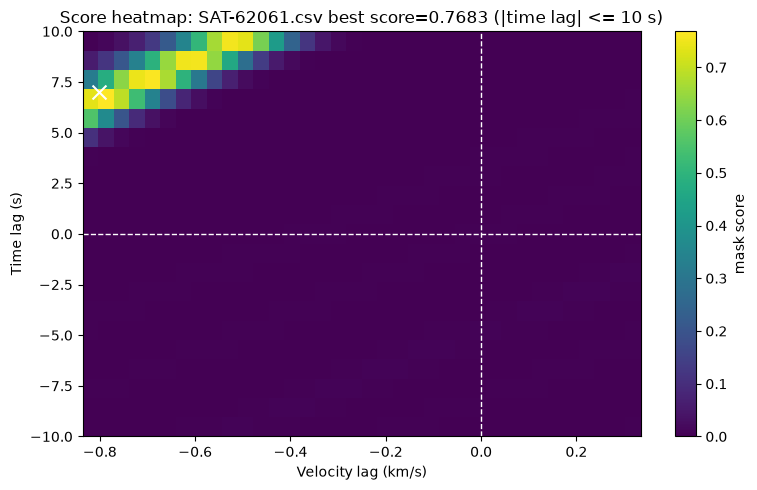

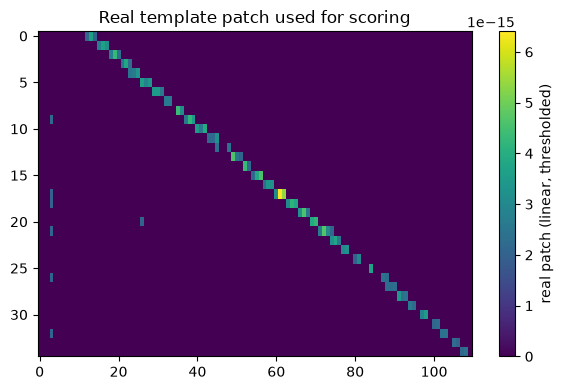

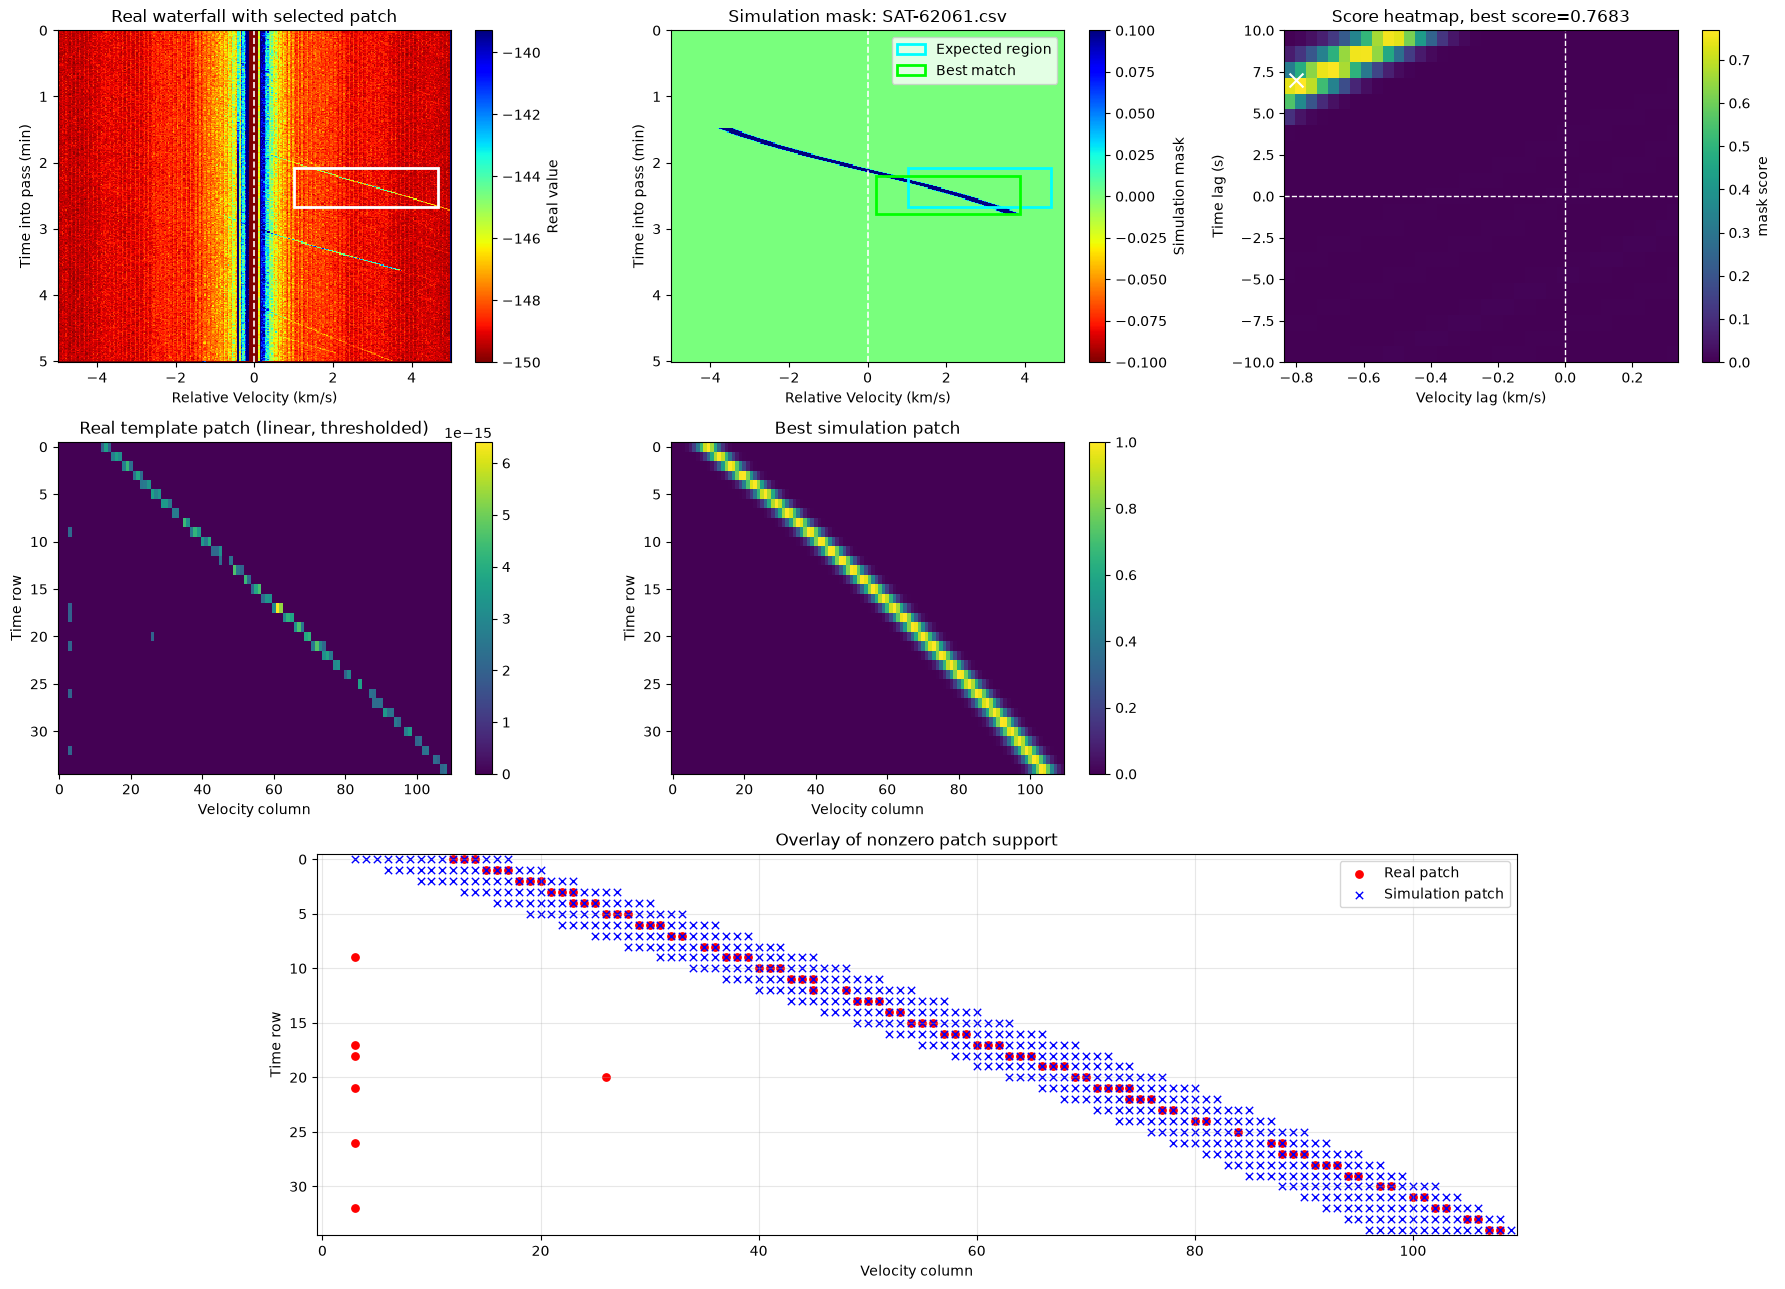

In [35]:
# ------------------------------------------------------------
# Optional debug plots for the selected top match
# ------------------------------------------------------------
def _ranking_score(payload):
    score = payload.get('best_score_limited', np.nan)
    return score if np.isfinite(score) else -np.inf

if MAKE_HEATMAP_FOR_TOP_MATCH and heatmap_payloads:
    ranking = sorted(heatmap_payloads, key=_ranking_score, reverse=True)
    payload = ranking[min(TOP_MATCH_RANK, len(ranking) - 1)]

    i0 = payload.get('best_i_limited')
    j0 = payload.get('best_j_limited')
    if i0 is None or j0 is None:
        raise ValueError('Selected match has no restricted best. Increase MAX_ABS_TIME_LAG_SEC or choose another rank.')

    h, w = payload['real_patch'].shape
    sim_patch = payload['sim_search'][i0:i0 + h, j0:j0 + w]

    if SAVE_DEBUG_PATCHES:
        debug_dir = Path(DEBUG_DIR)
        debug_dir.mkdir(parents=True, exist_ok=True)
        np.save(debug_dir / 'real_patch.npy', payload['real_patch'])
        np.save(debug_dir / 'sim_patch.npy', sim_patch)
        print('Saved:')
        print(f' - {debug_dir / "real_patch.npy"}')
        print(f' - {debug_dir / "sim_patch.npy"}')

    score_map = payload['score_map']
    lag_t_sec = payload['lag_t_sec']
    lag_v_kms = payload['lag_v_kms']
    t_mask = np.abs(lag_t_sec) <= MAX_ABS_TIME_LAG_SEC

    plt.figure(figsize=(8, 5))
    plt.imshow(
        score_map[t_mask, :],
        aspect='auto',
        origin='lower',
        extent=[lag_v_kms[0], lag_v_kms[-1], lag_t_sec[t_mask][0], lag_t_sec[t_mask][-1]],
        interpolation='nearest',
    )
    plt.colorbar(label='mask score')
    plt.scatter(payload['best_lag_v_kms_limited'], payload['best_lag_t_sec_limited'], marker='x', s=100, color='white')
    plt.axvline(0, linestyle='--', linewidth=1, color='white')
    plt.axhline(0, linestyle='--', linewidth=1, color='white')
    plt.xlabel('Velocity lag (km/s)')
    plt.ylabel('Time lag (s)')
    plt.title(
        f"Score heatmap: {payload['file']} "
        f"best score={payload['best_score_limited']:.4f} "
        f"(|time lag| <= {MAX_ABS_TIME_LAG_SEC:g} s)"
    )
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.imshow(payload['real_patch'], aspect='auto', origin='upper')
    plt.colorbar(label='real patch (linear, thresholded)')
    plt.title('Real template patch used for scoring')
    plt.tight_layout()
    plt.show()

    plot_satellite_match(
        payload['file'],
        heatmap_payloads,
        vel_centers_kms,
        t1hz,
        TIME_SLICE,
        VEL_SLICE,
        best_i=payload['best_i_limited'],
        best_j=payload['best_j_limited'],
        best_score=payload['best_score_limited'],
        best_lag_t_sec=payload['best_lag_t_sec_limited'],
        best_lag_v_kms=payload['best_lag_v_kms_limited'],
        max_abs_time_lag_sec=MAX_ABS_TIME_LAG_SEC,
    )
elif MAKE_HEATMAP_FOR_TOP_MATCH:
    print('No matches available to plot.')


## Sigma sweep test bench

This cell block sweeps `SIM_SIGMA_KMS` and summarizes:
- best (top) score per sigma,
- second-best score per sigma,
- top-vs-second score gap,
- a combined rank score balancing score gap and absolute top score.

It runs independently of the main matching cell so you can use it as a separate test area.

In [36]:
# ------------------------------------------------------------
# Sigma sweep test bench (independent run)
# ------------------------------------------------------------
SIGMA_SWEEP_VALUES = np.round(np.linspace(0.03, 0.2, 18), 3)
COMBINED_WEIGHT_GAP = 0.65
COMBINED_WEIGHT_TOP = 0.35

# Load and preprocess real data once
real_spec = np.load(REAL_WATERFALL_PATH)
time_axis = np.load(REAL_TIME_AXIS_PATH)
vel_axis = np.load(REAL_VELOCITY_AXIS_PATH) / 1000.0

real_1hz, vel_centers_kms, t1hz = downsample_real_to_1hz_and_resample(
    real_spec,
    time_axis,
    vel_axis,
    method=DOWNSAMPLE_METHOD,
    n_vel_out=N_VEL_OUT,
)
if FLIP_REAL_VELOCITY:
    real_1hz = np.flip(real_1hz, axis=1)

validate_slice('TIME_SLICE', TIME_SLICE, real_1hz.shape[0])
validate_slice('VEL_SLICE', VEL_SLICE, real_1hz.shape[1])

start_t, end_t = TIME_SLICE
start_v, end_v = VEL_SLICE

if SEARCH_MARGIN_T is None:
    search_t0, search_t1 = 0, real_1hz.shape[0]
else:
    search_t0 = max(0, start_t - int(SEARCH_MARGIN_T))
    search_t1 = min(real_1hz.shape[0], end_t + int(SEARCH_MARGIN_T))

if SEARCH_MARGIN_V is None:
    search_v0, search_v1 = 0, real_1hz.shape[1]
else:
    search_v0 = max(0, start_v - int(SEARCH_MARGIN_V))
    search_v1 = min(real_1hz.shape[1], end_v + int(SEARCH_MARGIN_V))

real_lin = linearize(real_1hz, source_mode=REAL_SOURCE_MODE)
real_patch_raw = real_lin[start_t:end_t, start_v:end_v]
real_patch = zero_mask(real_patch_raw, REAL_LINEAR_THRESHOLD)

if not np.any(real_patch):
    raise ValueError('The real template patch is empty after thresholding. Lower REAL_LINEAR_THRESHOLD.')

sim_csvs = list_simulation_csvs(SIM_DATA_ROOT, SIM_RUN_FILTER)
print(f'Found {len(sim_csvs)} simulation CSV files for sweep')

rows = []

for sigma in SIGMA_SWEEP_VALUES:
    candidate_rows = []

    for csv_path in sim_csvs:
        try:
            sim_1hz = build_sim_pdf_mask_on_real_axes(
                csv_path=csv_path,
                t1hz_utc=t1hz,
                vel_centers_kms=vel_centers_kms,
                sigma_kms=float(sigma),
                fill_empty=SIM_MASK_FILL_EMPTY,
            )
        except Exception as exc:
            if VERBOSE_SKIPS:
                print(f'Skipping {csv_path.name} @ sigma={sigma:.3f}: {exc}')
            continue

        sim_search = sim_1hz[search_t0:search_t1, search_v0:search_v1]
        score_map, score, best_i_local, best_j_local = sliding_window_mask_score_2d(
            real_patch,
            sim_search,
            max_time_lag_rows=MAX_TIME_LAG_ROWS,
        )

        if not np.isfinite(score):
            continue

        best_i_abs = search_t0 + best_i_local
        best_lag_t = best_i_abs - start_t
        best_lag_t_sec = float(best_lag_t)

        if abs(best_lag_t_sec) > MAX_ABS_TIME_LAG_SEC:
            continue

        candidate_rows.append({
            'file': csv_path.name,
            'score_2d': float(score),
        })

    if len(candidate_rows) == 0:
        rows.append({
            'sigma_kms': float(sigma),
            'n_candidates': 0,
            'top_file': None,
            'top_score': np.nan,
            'second_file': None,
            'second_score': np.nan,
            'top_minus_second': np.nan,
        })
        continue

    df_sigma = pd.DataFrame(candidate_rows).sort_values('score_2d', ascending=False).reset_index(drop=True)

    top_file = df_sigma.loc[0, 'file']
    top_score = float(df_sigma.loc[0, 'score_2d'])

    if len(df_sigma) >= 2:
        second_file = df_sigma.loc[1, 'file']
        second_score = float(df_sigma.loc[1, 'score_2d'])
        gap = top_score - second_score
    else:
        second_file = None
        second_score = np.nan
        gap = np.nan

    rows.append({
        'sigma_kms': float(sigma),
        'n_candidates': int(len(df_sigma)),
        'top_file': top_file,
        'top_score': top_score,
        'second_file': second_file,
        'second_score': second_score,
        'top_minus_second': gap,
    })

sweep_df = pd.DataFrame(rows).sort_values('sigma_kms').reset_index(drop=True)

valid = sweep_df['n_candidates'] >= 2
if valid.any():
    gap_vals = sweep_df.loc[valid, 'top_minus_second']
    top_vals = sweep_df.loc[valid, 'top_score']

    gap_span = max(float(gap_vals.max() - gap_vals.min()), 1e-12)
    top_span = max(float(top_vals.max() - top_vals.min()), 1e-12)

    sweep_df['gap_norm'] = np.nan
    sweep_df['top_norm'] = np.nan
    sweep_df['combined_rank_score'] = np.nan

    sweep_df.loc[valid, 'gap_norm'] = (sweep_df.loc[valid, 'top_minus_second'] - gap_vals.min()) / gap_span
    sweep_df.loc[valid, 'top_norm'] = (sweep_df.loc[valid, 'top_score'] - top_vals.min()) / top_span
    sweep_df.loc[valid, 'combined_rank_score'] = (
        COMBINED_WEIGHT_GAP * sweep_df.loc[valid, 'gap_norm']
        + COMBINED_WEIGHT_TOP * sweep_df.loc[valid, 'top_norm']
    )

    best_idx = sweep_df['combined_rank_score'].idxmax()
    recommended = sweep_df.loc[best_idx]

    print('\nRecommended sigma (gap+score balance):')
    print(
        f"sigma={recommended['sigma_kms']:.3f}, "
        f"top={recommended['top_score']:.6f}, "
        f"second={recommended['second_score']:.6f}, "
        f"gap={recommended['top_minus_second']:.6f}, "
        f"combined={recommended['combined_rank_score']:.4f}"
    )
else:
    sweep_df['gap_norm'] = np.nan
    sweep_df['top_norm'] = np.nan
    sweep_df['combined_rank_score'] = np.nan
    print('\nNo sigma values produced at least 2 valid candidates under current constraints.')

summary_cols = [
    'sigma_kms',
    'top_minus_second',
    'top_score',
    'top_file',
    'second_score',
    'second_file',
    'combined_rank_score',
]

print('\nSigma sweep summary:')
print(sweep_df[summary_cols].to_string(index=False, float_format=lambda x: f'{x:.6f}'))

# Optional: save table
sweep_out = Path(OUTPUT_DIR) / 'sigma_sweep_summary.csv'
sweep_df.to_csv(sweep_out, index=False)
print(f'\nSaved: {sweep_out}')

Found 148 simulation CSV files for sweep

Recommended sigma (gap+score balance):
sigma=0.080, top=0.801283, second=0.624073, gap=0.177210, combined=0.7195

Sigma sweep summary:
 sigma_kms  top_minus_second  top_score      top_file  second_score   second_file  combined_rank_score
  0.030000          0.195278   0.543878 SAT-62061.csv      0.348600 SAT-63493.csv             0.596344
  0.040000          0.204180   0.617787 SAT-62061.csv      0.413607 SAT-63493.csv             0.716624
  0.050000          0.194619   0.678162 SAT-62061.csv      0.483543 SAT-63493.csv             0.713422
  0.060000          0.186073   0.726635 SAT-62061.csv      0.540562 SAT-63493.csv             0.705607
  0.070000          0.181655   0.768281 SAT-62061.csv      0.586626 SAT-63493.csv             0.716520
  0.080000          0.177210   0.801283 SAT-62061.csv      0.624073 SAT-63493.csv             0.719477
  0.090000          0.172553   0.827520 SAT-62061.csv      0.654967 SAT-63493.csv             0.715056